# 07 - Parties and accounts

**Question:** how does the generator create the parties (business B / consumer C), their accounts, and who pays whom?

Works on the `feat` view through `src/eda.py`, **normal payments only** unless stated (account formats use every row). Charts are saved with the prefix `P`.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda

eda.connect()  # in-memory DuckDB in UTC with views tx (clean) and feat (clean + features). If RAM runs out: eda.connect(memory_limit="3GB")
eda.require_columns("feat", ["party_pair", "sender_country", "receiver_country"])
q, save = eda.q, eda.save

# Normal payments only: the rules in this notebook describe regular traffic (anomalies are in 02_anomaly_types)
eda.con.execute("CREATE OR REPLACE VIEW normal AS SELECT * FROM feat WHERE is_anomaly = 0")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


## 1. Sanity check

In [2]:
checks = q("""
    SELECT count(*)                                AS rows,
           count(*) FILTER (WHERE is_anomaly = 0)  AS normal_rows,
           min(epoch_seconds)                      AS first_payment,
           max(epoch_seconds)                      AS last_payment
    FROM feat
""")
assert checks.loc[0, "rows"] == 10_000_000
assert checks.loc[0, "normal_rows"] == 9_992_994
checks

,rows,normal_rows,first_payment,last_payment
0,10000000,9992994,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


## Hypotheses (written before testing)

| ID | Hypothesis | Test |
|---|---|---|
| H-P1 | Who receives depends on who sends (e.g. businesses mostly pay businesses) | Party-pair shares vs the shares expected if sender type and receiver type were independent (P1) |
| H-P2 | Each account belongs to one party with one fixed type | Type consistency per account, within and across the sending and receiving role (P2) |
| H-P3 | A few accounts make most of the payments, and businesses are more active than consumers | Payments per account by type; concentration; shape of the tail (P3) |
| H-P4 | Businesses pay the same payees again more often than consumers (suppliers, payroll) | Repeat-payee rate by party pair, then within the same activity level (P4) |
| H-P5 | The account number format depends on the bank's country (IBAN countries vs others) | IBAN share per bank country; IBAN length, structure and check digits (P5) |

## P1. Are sender type and receiver type independent? (H-P1)

In [3]:
p1 = q("SELECT party_pair, ordering_type, beneficiary_type, count(*) AS n FROM normal GROUP BY 1, 2, 3 ORDER BY 1")
total = p1.n.sum()
p_sender = p1.groupby("ordering_type").n.sum() / total
p_receiver = p1.groupby("beneficiary_type").n.sum() / total
p1["observed_pct"] = p1.n / total * 100
p1["expected_if_independent_pct"] = [p_sender[o] * p_receiver[b] * 100 for o, b in zip(p1.ordering_type, p1.beneficiary_type)]
p1["difference_pts"] = p1.observed_pct - p1.expected_if_independent_pct
chi2 = (((p1.n - p1.expected_if_independent_pct / 100 * total) ** 2) / (p1.expected_if_independent_pct / 100 * total)).sum()
print(f"Sender is a business: {p_sender['B'] * 100:.2f}%   Receiver is a business: {p_receiver['B'] * 100:.2f}%")
print(f"Chi-square (1 degree of freedom) = {chi2:.1f}; Cramer's V = {np.sqrt(chi2 / total):.5f} (0 = fully independent)")
p1.round(3)

Sender is a business: 78.76%   Receiver is a business: 28.82%
Chi-square (1 degree of freedom) = 9.1; Cramer's V = 0.00096 (0 = fully independent)


,party_pair,ordering_type,beneficiary_type,n,observed_pct,expected_if_independent_pct,difference_pts
0,B2B,B,B,2269885,22.715,22.697,0.018
1,B2C,B,C,5600965,56.049,56.067,-0.018
2,C2B,C,B,609762,6.102,6.120,-0.018
3,C2C,C,C,1512382,15.134,15.117,0.018


## P2. Does the party type belong to the account or to the role? (H-P2)
An account can appear as a sender (`ordering_account`) and as a receiver (`beneficiary_account`). All rows are used here.

In [4]:
p2 = q("""
    WITH o AS (SELECT ordering_account AS acc, count(DISTINCT ordering_type) AS types,
                      any_value(ordering_type) AS t, any_value(ordering_bic8) AS bank
               FROM feat GROUP BY 1),
         b AS (SELECT beneficiary_account AS acc, count(DISTINCT beneficiary_type) AS types,
                      any_value(beneficiary_type) AS t, arg_max(beneficiary_bic8, epoch_seconds) AS bank
               FROM feat GROUP BY 1),
         both_roles AS (SELECT o.t AS t_send, b.t AS t_recv, o.bank = b.bank AS same_bank FROM o JOIN b USING (acc))
    SELECT (SELECT count(*) FROM o)                          AS sending_accounts,
           (SELECT count(*) FROM o WHERE types > 1)          AS sending_accounts_with_2_types,
           (SELECT count(*) FROM b)                          AS receiving_accounts,
           (SELECT count(*) FROM b WHERE types > 1)          AS receiving_accounts_with_2_types,
           (SELECT count(*) FROM both_roles)                 AS accounts_in_both_roles,
           (SELECT 100 * avg(same_bank::INT) FROM both_roles) AS pct_same_bank_in_both_roles,
           (SELECT 100 * avg((t_send = t_recv)::INT) FROM both_roles) AS pct_same_type_in_both_roles,
           (SELECT 100 * (avg((t_send = 'B')::INT) * avg((t_recv = 'B')::INT)
                        + avg((t_send = 'C')::INT) * avg((t_recv = 'C')::INT)) FROM both_roles) AS pct_same_type_if_random
""")
p2.T.round(2)

,0
sending_accounts,391132.00
sending_accounts_with_2_types,0.00
receiving_accounts,2590877.00
receiving_accounts_with_2_types,0.00
accounts_in_both_roles,253120.00
pct_same_bank_in_both_roles,99.92
pct_same_type_in_both_roles,49.60
pct_same_type_if_random,49.92


## P3. How active is each account? (H-P3)

In [5]:
p3 = q("""
    WITH s AS (SELECT ordering_account, any_value(ordering_type) AS t, count(*) AS n FROM normal GROUP BY 1)
    SELECT 'sender' AS role, t AS type, count(*) AS accounts, avg(n) AS mean_payments, median(n) AS median_payments,
           quantile_disc(n, 0.99) AS p99, max(n) AS max_payments, sum(n) AS payments FROM s GROUP BY 2
    UNION ALL
    SELECT 'receiver', t, count(*), avg(n), median(n), quantile_disc(n, 0.99), max(n), sum(n)
    FROM (SELECT beneficiary_account, any_value(beneficiary_type) AS t, count(*) AS n FROM normal GROUP BY 1) GROUP BY 2
    ORDER BY 1 DESC, 2
""")
conc = q("""
    WITH s AS (SELECT count(*) AS n FROM normal GROUP BY ordering_account),
    r AS (SELECT n, row_number() OVER (ORDER BY n DESC) AS rk, count(*) OVER () AS accounts FROM s)
    SELECT 100 * sum(n) FILTER (WHERE rk <= accounts * 0.01) / sum(n) AS top_1pct_of_senders_share,
           100 * sum(n) FILTER (WHERE rk <= accounts * 0.10) / sum(n) AS top_10pct_of_senders_share
    FROM r
""")
display(conc.round(1))
p3.round(2)

,top_1pct_of_senders_share,top_10pct_of_senders_share
0,45.9,82.7


,role,type,accounts,mean_payments,median_payments,p99,max_payments,payments
0,sender,B,175563,44.83,4.0,689,75773,7870850.0
1,sender,C,215162,9.86,2.0,126,14549,2122144.0
2,receiver,B,761652,3.78,1.0,39,34326,2879647.0
3,receiver,C,1828105,3.89,1.0,40,53336,7113347.0


{'sender B': np.float64(-0.99), 'sender C': np.float64(-1.31), 'receiver B': np.float64(-1.15), 'receiver C': np.float64(-1.13)}


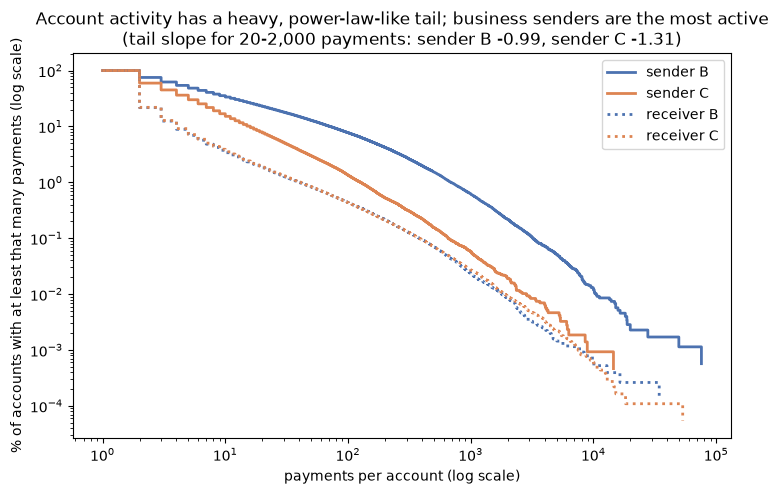

In [6]:
counts = q("""
    SELECT 'sender ' || ordering_type AS grp, count(*) AS n FROM normal GROUP BY ordering_account, ordering_type
    UNION ALL
    SELECT 'receiver ' || beneficiary_type, count(*) FROM normal GROUP BY beneficiary_account, beneficiary_type
""")
fig, ax = plt.subplots(figsize=(8.5, 5))
slopes = {}
for grp, col, ls in [("sender B", "#4C72B0", "-"), ("sender C", "#DD8452", "-"), ("receiver B", "#4C72B0", ":"), ("receiver C", "#DD8452", ":")]:
    x_all = np.sort(counts.loc[counts.grp == grp, "n"].to_numpy())
    x, first = np.unique(x_all, return_index=True)
    ccdf = 1 - first / len(x_all)  # share of accounts with at least x payments
    ax.loglog(x, ccdf * 100, color=col, ls=ls, lw=2, drawstyle="steps-post", label=grp)
    # tail slope on an even log grid from 20 to 2,000 payments (a range every group still reaches)
    grid = np.logspace(np.log10(20), np.log10(2000), 21)
    share_at_least = 1 - np.searchsorted(x_all, grid, side="left") / len(x_all)
    slopes[grp] = np.polyfit(np.log10(grid), np.log10(share_at_least), 1)[0]
ax.set_xlabel("payments per account (log scale)")
ax.set_ylabel("% of accounts with at least that many payments (log scale)")
ax.legend()
ax.set_title("Account activity has a heavy, power-law-like tail; business senders are the most active\n"
             f"(tail slope for 20-2,000 payments: sender B {slopes['sender B']:.2f}, sender C {slopes['sender C']:.2f})")
print({k: round(v, 2) for k, v in slopes.items()})
save(fig, "P3_account_activity")
plt.show()

## P4. Repeat payees (H-P4)
A payment is a *repeat* when the same sender already paid the same receiver earlier. The raw comparison by party pair is followed by a control for how many payments the sender makes.

In [7]:
p4 = q("""
    WITH a AS (SELECT ordering_account, count(*) AS sent FROM normal GROUP BY 1),
    x AS (SELECT n.party_pair, n.ordering_type, a.sent,
                 row_number() OVER (PARTITION BY n.ordering_account, n.beneficiary_account ORDER BY n.epoch_seconds) AS k
          FROM normal n JOIN a USING (ordering_account))
    SELECT party_pair, ordering_type,
           CASE WHEN sent < 5 THEN '1-4' WHEN sent < 20 THEN '5-19' WHEN sent < 100 THEN '20-99'
                WHEN sent < 1000 THEN '100-999' ELSE '1000+' END AS sender_activity,
           count(*) AS n, sum((k > 1)::INT) AS repeats
    FROM x GROUP BY 1, 2, 3
""")
raw = p4.groupby("party_pair")[["n", "repeats"]].sum()
raw["pct_repeat"] = raw.repeats / raw.n * 100
order = ["1-4", "5-19", "20-99", "100-999", "1000+"]
ctrl = p4.groupby(["sender_activity", "ordering_type"])[["n", "repeats"]].sum()
ctrl["pct_repeat"] = ctrl.repeats / ctrl.n * 100
ctrl = ctrl["pct_repeat"].unstack().loc[order]
display(raw.round(2))
ctrl.round(2)  # % repeat payments, by sender activity (payments sent) and sender type

,n,repeats,pct_repeat
party_pair,,,
B2B,2269885,410442.0,18.08
B2C,5600965,1080796.0,19.30
C2B,609762,65611.0,10.76
C2C,1512382,177665.0,11.75


ordering_type,B,C
sender_activity,,
1-4,0.84,0.64
5-19,3.83,3.35
20-99,8.91,8.68
100-999,17.82,17.54
1000+,28.34,26.52


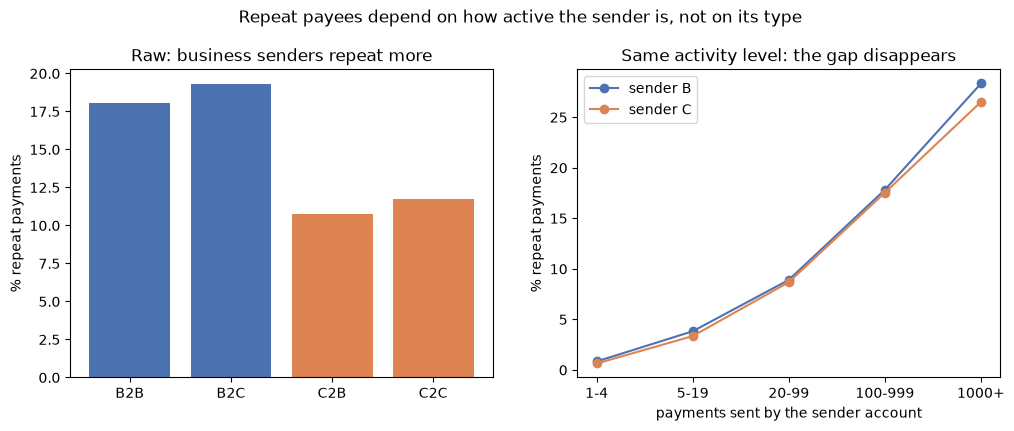

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(raw.index, raw.pct_repeat, color=["#4C72B0", "#4C72B0", "#DD8452", "#DD8452"])
axes[0].set_ylabel("% repeat payments")
axes[0].set_title("Raw: business senders repeat more")
for t, col in [("B", "#4C72B0"), ("C", "#DD8452")]:
    axes[1].plot(order, ctrl[t], marker="o", color=col, label=f"sender {t}")
axes[1].set_xlabel("payments sent by the sender account")
axes[1].set_ylabel("% repeat payments")
axes[1].set_title("Same activity level: the gap disappears")
axes[1].legend()
fig.suptitle("Repeat payees depend on how active the sender is, not on its type", y=1.03)
save(fig, "P4_repeat_payees")
plt.show()

## P5. Account number formats (H-P5)
An account is IBAN-like when, after the `_FAKE_` prefix, it starts with 2 letters and 2 digits. Every row (normal and anomalies) and both roles are used.

In [9]:
p5 = q("""
    WITH a AS (
        SELECT ordering_account AS acc, ordering_bic8 AS bic FROM feat
        UNION
        SELECT beneficiary_account, beneficiary_bic8 FROM feat
    ),
    x AS (SELECT substr(bic, 5, 2) AS country, regexp_matches(substr(acc, 7), '^[A-Z]{2}[0-9]{2}') AS is_iban FROM a)
    SELECT country, count(*) AS accounts, avg(is_iban::INT) AS iban_share FROM x GROUP BY 1
""")
print(f"Bank countries: {len(p5)}")
print(f"  100% IBAN accounts: {(p5.iban_share == 1).sum()}")
print(f"    0% IBAN accounts: {(p5.iban_share == 0).sum()}")
print(f"  mixed:              {((p5.iban_share > 0) & (p5.iban_share < 1)).sum()}")
p5.groupby(p5.iban_share == 1).country.apply(lambda s: ", ".join(sorted(s)[:25]) + (" ..." if len(s) > 25 else "")).rename(
    index={True: "IBAN countries", False: "non-IBAN countries"}).to_frame("bank countries (first 25)")

Bank countries: 229
  100% IBAN accounts: 76
    0% IBAN accounts: 153
  mixed:              0


,bank countries (first 25)
iban_share,
non-IBAN countries,"AF, AG, AI, AM, AO, AR, AU, AW, BB, BD, BF, BI..."
IBAN countries,"AD, AE, AL, AT, AZ, BA, BE, BG, BH, BR, BY, CH..."


In [10]:
ibans = q("""
    WITH a AS (
        SELECT ordering_account AS acc, ordering_bic8 AS bic FROM feat
        UNION
        SELECT beneficiary_account, beneficiary_bic8 FROM feat
    )
    SELECT DISTINCT rtrim(substr(acc, 7)) AS iban, bic FROM a WHERE regexp_matches(substr(acc, 7), '^[A-Z]{2}[0-9]{2}')
""")


def mod97_valid(s: str) -> bool:
    """ISO 13616 check: move the first 4 characters to the end, letters -> numbers (A=10 ... Z=35), remainder mod 97 must be 1."""
    r = s[4:] + s[:4]
    return int("".join(str(int(ch, 36)) for ch in r)) % 97 == 1


p5b = pd.Series({
    "IBAN accounts (distinct account + bank)": len(ibans),
    "length is 22 characters (%)": (ibans.iban.str.len() == 22).mean() * 100,
    "country code = bank's BIC country (%)": (ibans.iban.str[:2] == ibans.bic.str[4:6]).mean() * 100,
    "characters 5-8 = bank's BIC digits 1-4 (%)": (ibans.iban.str[4:8] == ibans.bic.str[:4]).mean() * 100,
    "characters 9-16 are all zeros (%)": (ibans.iban.str[8:16] == "00000000").mean() * 100,
    "characters 17-22 are digits (%)": ibans.iban.str[16:22].str.fullmatch(r"\d{6}").mean() * 100,
    "valid ISO 13616 check digits (%)": ibans.iban.map(mod97_valid).mean() * 100,
})
print("Example:", ibans.iban.iloc[0], "at bank", ibans.bic.iloc[0])
p5b.round(2).to_frame("value")

Example: IL59000700000000418129 at bank 0007ILI0


,value
IBAN accounts (distinct account + bank),1380259.00
length is 22 characters (%),100.00
country code = bank's BIC country (%),100.00
characters 5-8 = bank's BIC digits 1-4 (%),100.00
characters 9-16 are all zeros (%),100.00
characters 17-22 are digits (%),100.00
valid ISO 13616 check digits (%),1.03


In [11]:
p5c = q('''
    WITH a AS (
        SELECT ordering_account AS acc, ordering_bic8 AS bic FROM feat
        UNION
        SELECT beneficiary_account, beneficiary_bic8 FROM feat
    )
    SELECT substr(bic, 5, 2) AS country, count(*) AS accounts,
           min(length(acc)) AS min_length, max(length(acc)) AS max_length,
           100 * avg((acc <> rtrim(acc))::INT) AS pct_trailing_spaces,
           list(acc ORDER BY acc)[1:2] AS examples
    FROM a
    WHERE NOT regexp_matches(substr(acc, 7), '^[A-Z]{2}[0-9]{2}')
      AND substr(bic, 5, 2) IN ('US', 'CN', 'JP', 'AU', 'IN', 'CA', 'SG', 'HK')
    GROUP BY 1 ORDER BY accounts DESC
''')
ok = q("SELECT bool_and(starts_with(ordering_account, '_FAKE_') AND starts_with(beneficiary_account, '_FAKE_')) AS ok FROM feat").ok[0]
print("Every account starts with '_FAKE_':", ok)
p5c  # non-IBAN countries: free-form account numbers

Every account starts with '_FAKE_': True


,country,accounts,min_length,max_length,pct_trailing_spaces,examples
0,US,493719,12,26,6.836480,"[_FAKE_ 00000USD1/8/8.75, _FAKE_ 00000USD3/6..."
1,CN,161946,12,26,5.451200,"[_FAKE_ .00103731, _FAKE_ .00184973]"
2,SG,89031,12,26,0.075255,"[_FAKE_ .00000003, _FAKE_ .00000007]"
3,JP,57889,12,26,6.329354,"[_FAKE_ .00007086, _FAKE_ .00024305]"
4,IN,47612,12,26,1.176174,"[_FAKE_ 00000INR0/4/7.12, _FAKE_ 00000INR0/7..."
5,HK,45591,12,26,9.835275,"[_FAKE_ 00000HKD0/0/4.80, _FAKE_ 00000HKD0/7..."
6,AU,43954,12,26,0.179733,"[_FAKE_ .00019492, _FAKE_ .00317618]"
7,CA,31381,12,26,4.483605,"[_FAKE_ 00000CAD8/4/9.67, _FAKE_ 0084104]"


## P6. Results → rules

| ID | Condition | Effect | Size | Rows | Confidence |
|---|---|---|---|---|---|
| R-P1 | Every payment | Sender type and receiver type are drawn **independently**: sender B 78.8% / C 21.2%, receiver B 28.8% / C 71.2%. Party-pair shares equal the products (B2C 56.0%, B2B 22.7%, C2C 15.1%, C2B 6.1%) | Largest gap 0.02 pts; Cramer's V = 0.001 | 9,992,994 | High |
| R-P2 | Each account within one role | Type is fixed per account per role (0 accounts with 2 types as sender or as receiver), but drawn **separately for each role**: accounts used in both roles keep the same bank (99.92%) yet the same type only 49.6% of the time, the 49.9% expected by chance | 253,120 accounts in both roles | all 10,000,000 | High |
| R-P3 | Sending accounts | Activity is heavy-tailed: top 1% of senders make 45.9% of payments, top 10% make 82.7%. Business senders are ~4.5x more active (mean 44.8 vs 9.9; median 4 vs 2; max 75,773). Receivers are light for both types (mean ~3.8, median 1) | Tail slope about -1.0 (B) and -1.3 (C) on log-log | 9,992,994 | High |
| R-P4 | Repeat payee (same sender paid the same receiver before) | Probability rises with how many payments the sender makes: under 1% (1-4 payments) → ~9% (20-99) → 26.5-28.3% (1000+), **almost the same for B and C**. The raw gap (B 18-19% vs C 11-12%) comes from B senders being more active | B vs C within an activity level: at most 1.8 pts | 9,992,994 | High |
| R-P5 | Bank country | Account format is set by the bank's country: 76 countries always IBAN, 153 never, 0 mixed. Every account starts with `_FAKE_`; non-IBAN accounts are free-form, 6-20 characters after the prefix (some contain the currency code, ~4.6% end in spaces), the same pattern in every non-IBAN country | 100% | all 10,000,000 | High |
| R-P6 | IBAN countries | Template = country code (= bank's BIC country) + 2 check digits + BIC bank code (4 chars) + `00000000` + 6 digits, always **22 characters**. The check digits are random: only 1.03% pass ISO 13616, the 1-in-97 chance | 100% template; 1.03% valid | 1,380,259 IBAN accounts | High |

**Did not hold**
- **H-P1** (receiver depends on sender): rejected, the two types are independent (R-P1).
- **H-P2** (one fixed type per account): only within a role; the same account can be B as a sender and C as a receiver (R-P2).
- **H-P4** (businesses re-pay the same payees more): rejected after controlling for activity (R-P4).
- **H-P5, partly**: the IBAN *format* depends on the country, but not the real standard: real IBAN lengths differ by country (e.g. FR 27, CH 21, SA 24, TR 26) and real check digits always validate.